Task 2: Real Estate Housing Price Prediction
Objective
Predict median house values using regression models and compare Ordinary Least Squares (OLS), Ridge Regression, and Lasso Regression.

Tools and Libraries
Python
Pandas
NumPy
Seaborn
Matplotlib
Scikit-Learn
Models
Linear Regression (OLS)
Ridge Regression
Lasso Regression

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

In [2]:
df = pd.read_csv("housing.txt")

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [4]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [5]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

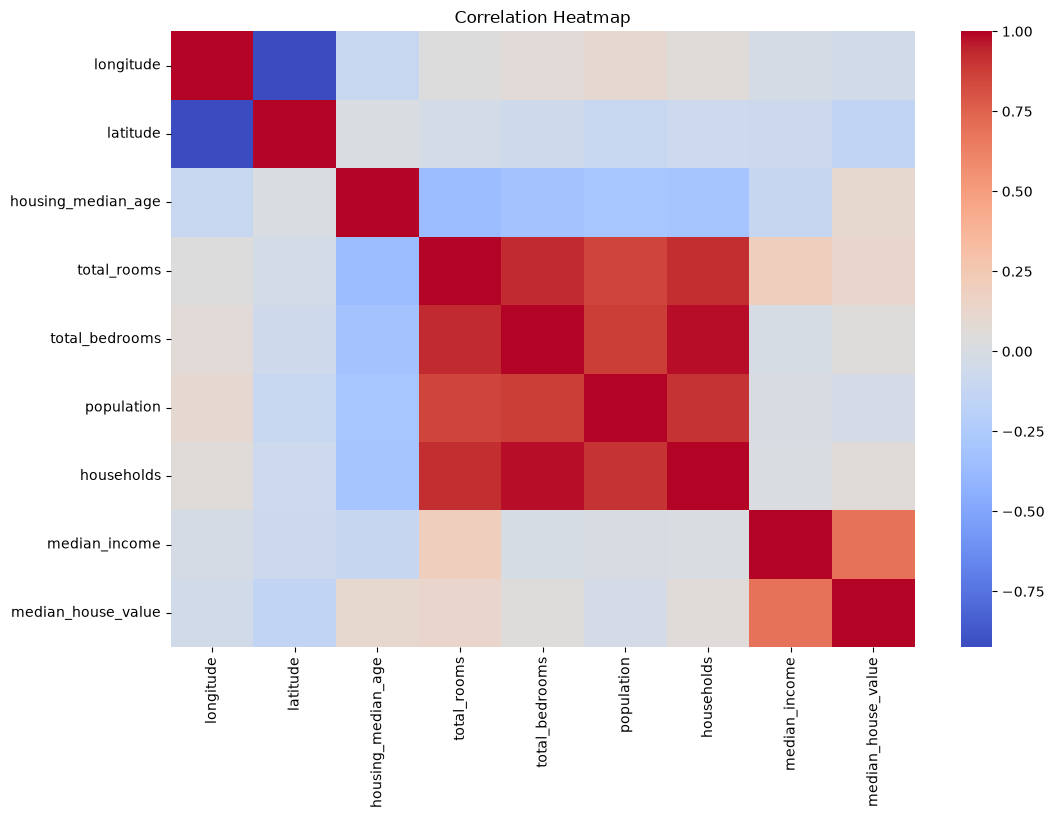

In [6]:
plt.figure(figsize=(12,8))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

In [7]:
df["rooms_per_household"] = (
    df["total_rooms"] / df["households"]
)

df["bedrooms_per_room"] = (
    df["total_bedrooms"] / df["total_rooms"]
)

df["population_per_household"] = (
    df["population"] / df["households"]
)

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,0.155797,2.109842
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,5.817352,0.184458,2.547945
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6.281853,0.172096,2.181467


In [8]:
X = df.drop(
    "median_house_value",
    axis=1
)

y = df["median_house_value"]

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(16512, 12)
(4128, 12)


In [10]:
num_cols = X.select_dtypes(
    include=np.number
).columns

cat_cols = X.select_dtypes(
    exclude=np.number
).columns

print("Numerical:", num_cols)
print("Categorical:", cat_cols)

Numerical: Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'rooms_per_household', 'bedrooms_per_room', 'population_per_household'],
      dtype='str')
Categorical: Index(['ocean_proximity'], dtype='str')


In [11]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, num_cols),
    ("cat", categorical_transformer, cat_cols)
])

In [12]:
ols_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

ols_pipeline.fit(
    X_train,
    y_train
)

ols_pred = ols_pipeline.predict(X_test)

print("OLS complete")

OLS complete


In [13]:
ols_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        ols_pred
    )
)

ols_mae = mean_absolute_error(
    y_test,
    ols_pred
)

ols_r2 = r2_score(
    y_test,
    ols_pred
)

print("RMSE:", ols_rmse)
print("MAE:", ols_mae)
print("R2:", ols_r2)

RMSE: 69127.03829924985
MAE: 49645.49244453642
R2: 0.635339233523819


In [14]:
ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

ridge_grid = GridSearchCV(
    ridge_pipeline,
    {
        "model__alpha":[0.01,0.1,1,10,100]
    },
    cv=5,
    scoring="r2"
)

ridge_grid.fit(
    X_train,
    y_train
)

ridge_pred = ridge_grid.predict(
    X_test
)

print(
    "Best Alpha:",
    ridge_grid.best_params_
)

Best Alpha: {'model__alpha': 1}


In [15]:
ridge_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        ridge_pred
    )
)

ridge_mae = mean_absolute_error(
    y_test,
    ridge_pred
)

ridge_r2 = r2_score(
    y_test,
    ridge_pred
)

print("RMSE:", ridge_rmse)
print("MAE:", ridge_mae)
print("R2:", ridge_r2)

RMSE: 69134.96527371781
MAE: 49652.14287272517
R2: 0.6352555955611363


In [18]:
lasso_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Lasso(max_iter=10000))
])

lasso_grid = GridSearchCV(
    lasso_pipeline,
    {
        "model__alpha": [1, 10]
    },
    cv=3,
    scoring="r2"
)

lasso_grid.fit(X_train, y_train)

lasso_pred = lasso_grid.predict(X_test)

print("Best Alpha:", lasso_grid.best_params_)

Best Alpha: {'model__alpha': 1}


In [19]:
lasso_rmse = np.sqrt(
    mean_squared_error(y_test, lasso_pred)
)

lasso_mae = mean_absolute_error(
    y_test,
    lasso_pred
)

lasso_r2 = r2_score(
    y_test,
    lasso_pred
)

print("RMSE:", lasso_rmse)
print("MAE:", lasso_mae)
print("R2:", lasso_r2)

RMSE: 69128.09124072836
MAE: 49646.42889325855
R2: 0.6353281244301753


In [20]:
comparison = pd.DataFrame({

    "Model": [
        "OLS",
        "Ridge",
        "Lasso"
    ],

    "RMSE": [
        ols_rmse,
        ridge_rmse,
        lasso_rmse
    ],

    "MAE": [
        ols_mae,
        ridge_mae,
        lasso_mae
    ],

    "R2": [
        ols_r2,
        ridge_r2,
        lasso_r2
    ]
})

comparison

,Model,RMSE,MAE,R2
0,OLS,69127.038299,49645.492445,0.635339
1,Ridge,69134.965274,49652.142873,0.635256
2,Lasso,69128.091241,49646.428893,0.635328


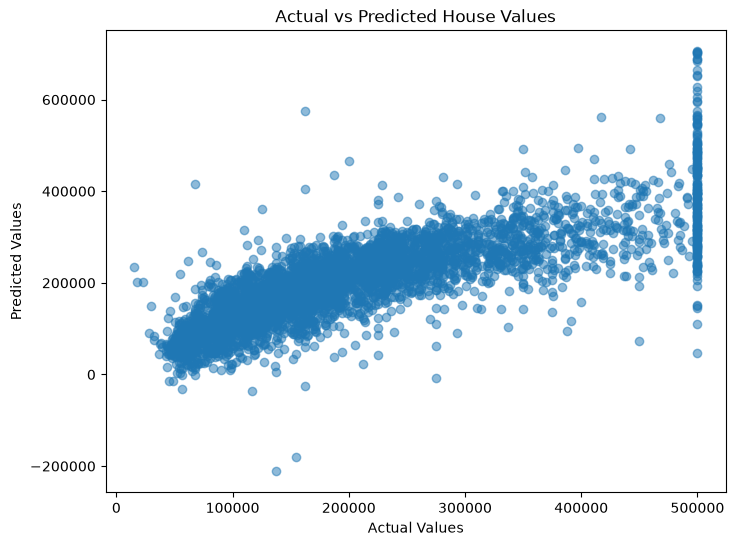

In [21]:
plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    ridge_pred,
    alpha=0.5
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted House Values")

plt.show()

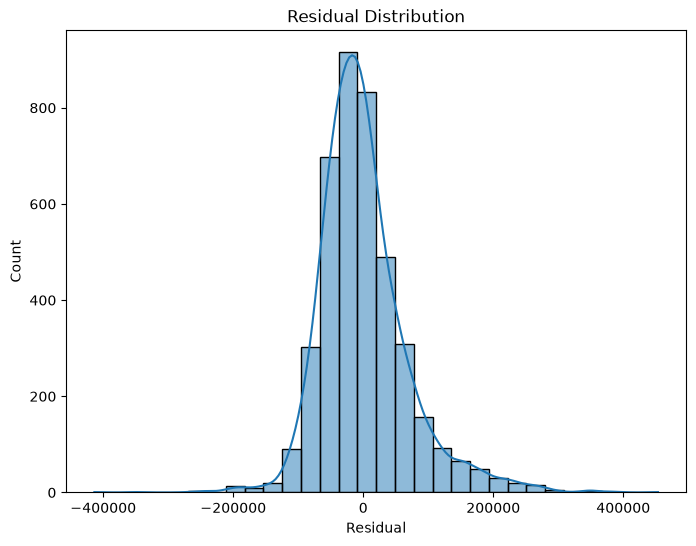

In [22]:
residuals = y_test - ridge_pred

plt.figure(figsize=(8,6))

sns.histplot(
    residuals,
    bins=30,
    kde=True
)

plt.title("Residual Distribution")
plt.xlabel("Residual")

plt.show()

Conclusion
This project developed and compared three regression models: Ordinary Least Squares (OLS), Ridge Regression, and Lasso Regression.

The dataset was preprocessed through missing value imputation, standardization, categorical encoding, and feature engineering. Additional variables capturing housing and population ratios were created to improve predictive performance.

Model performance was evaluated using RMSE, MAE, and R² metrics. Ridge and Lasso regularization helped address multicollinearity while maintaining strong predictive accuracy.

Overall, the models successfully predicted housing values using demographic, geographic, and housing characteristics from the California Housing dataset.